<h1>
<Center>
UTS Graf
</Center>
</h1>

Nama    : Rafael Hartono

NIM     : 24031554166


github link:

https://github.com/rafaelhartono8/graf_24031554166

In [1]:
!uv pip install -r requirements.txt

Using Python 3.12.13 environment at: /home/rafael/Documents/graf_24031554166/myenv
Checked 13 packages in 4ms


In [2]:
import os
import zipfile
import pandas as pd
from neo4j import GraphDatabase
import argparse
import sys
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

from tqdm import tqdm
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors


import seaborn as sns


In [3]:

if not os.path.exists("ecommerce-dataset.zip"):
    !curl -L -o ecommerce-dataset.zip \https://www.kaggle.com/api/v1/datasets/download/retailrocket/ecommerce-dataset

    print("File ecommerce-dataset.zip berhasil didownload")

else:
    print("File ecommerce-dataset.zip sudah ada")


if not os.path.exists("ecommerce-dataset"):

    with zipfile.ZipFile("ecommerce-dataset.zip", "r") as zip_ref:
        zip_ref.extractall("ecommerce-dataset")
    print("File ecommerce-dataset berhasil diextract")
else:
    print("File ecommerce-dataset sudah ada")

File ecommerce-dataset.zip sudah ada
File ecommerce-dataset sudah ada


In [4]:
print("Versi pandas:" , pd.__version__)

cat_tree = pd.read_csv("ecommerce-dataset/category_tree.csv")
print("Category Tree:")
print(cat_tree.head())

events = pd.read_csv("ecommerce-dataset/events.csv")
print("Events:")
print(events.head())

item_prop1 = pd.read_csv("ecommerce-dataset/item_properties_part1.csv")
print("Item Properties Part 1:")
print(item_prop1.head())

item_prop2 = pd.read_csv("ecommerce-dataset/item_properties_part2.csv")
print("Item Properties Part 2:")
print(item_prop2.head())

Versi pandas: 3.1.0
Category Tree:
   categoryid  parentid
0        1016     213.0
1         809     169.0
2         570       9.0
3        1691     885.0
4         536    1691.0
Events:
       timestamp  visitorid event  itemid  transactionid
0  1433221332117     257597  view  355908            NaN
1  1433224214164     992329  view  248676            NaN
2  1433221999827     111016  view  318965            NaN
3  1433221955914     483717  view  253185            NaN
4  1433221337106     951259  view  367447            NaN
Item Properties Part 1:
       timestamp  itemid    property                            value
0  1435460400000  460429  categoryid                             1338
1  1441508400000  206783         888          1116713 960601 n277.200
2  1439089200000  395014         400  n552.000 639502 n720.000 424566
3  1431226800000   59481         790                       n15360.000
4  1431831600000  156781         917                           828513
Item Properties Part 2:
   

In [5]:
print("Category Tree:")
print(cat_tree.head())

events["timestamp"] = pd.to_datetime(events["timestamp"], unit="ms")
events = events.sort_values("timestamp").reset_index()
print("Events:")
print(events.head())

item_prop1["timestamp"] = pd.to_datetime(item_prop1["timestamp"], unit="ms")
item_prop1 = item_prop1.sort_values("timestamp").reset_index()
print("Item Properties Part 1:")
print(item_prop1.head())

item_prop2["timestamp"] = pd.to_datetime(item_prop2["timestamp"], unit="ms")
item_prop2 = item_prop2.sort_values("timestamp").reset_index()
print("Item Properties Part 2:")
print(item_prop2.head())

Category Tree:
   categoryid  parentid
0        1016     213.0
1         809     169.0
2         570       9.0
3        1691     885.0
4         536    1691.0
Events:
     index               timestamp  visitorid      event  itemid  \
0  1462974 2015-05-03 03:00:04.384     693516  addtocart  297662   
1  1464806 2015-05-03 03:00:11.289     829044       view   60987   
2  1463000 2015-05-03 03:00:13.048     652699       view  252860   
3  1465287 2015-05-03 03:00:24.154    1125936       view   33661   
4  1462955 2015-05-03 03:00:26.228     693516       view  297662   

   transactionid  
0            NaN  
1            NaN  
2            NaN  
3            NaN  
4            NaN  
Item Properties Part 1:
      index           timestamp  itemid property                     value
0   8019207 2015-05-10 03:00:00  213522      159                    519769
1  10102067 2015-05-10 03:00:00  390382        6                   1206195
2   3649339 2015-05-10 03:00:00  339404      917       n70811

# 1. Tentukan 2 periode waktu sebagai filter dari data interaksi. Kombinasi periode yang dipilih tiap mahasiswa 

jawab: 
periode yang akan digunakan
Fold Training
P1 (16 Juni–31 Agt 2015)

Fold Testing
P2 (01 Sept–18 Sept 2015)


In [6]:
train_start, train_end = "2015-06-16 00:00:00", "2015-08-31 23:59:59"
test_start, test_end = "2015-09-01 00:00:00", "2015-09-18 23:59:59"


df_train = events[(events["timestamp"] >= train_start) & (events["timestamp"] <= train_end)]
df_test = events[(events["timestamp"] >= test_start) & (events["timestamp"] <= test_end)]

df_train["timestamp"] = df_train["timestamp"].dt.strftime("%Y-%m-%dT%H:%M:%S")
df_test["timestamp"] = df_test["timestamp"].dt.strftime("%Y-%m-%dT%H:%M:%S")

df_train = df_train.reset_index()
df_test = df_test.reset_index()


print(f"Train: {df_train.shape}")
print(df_train.head(1))
print(df_train.tail(1))



print(f"\nTest: {df_test.shape}")
print(df_test.head(1))
print(df_test.tail(1))

Train: (1561176, 7)
   level_0   index            timestamp  visitorid event  itemid  \
0   891215  265883  2015-06-16T00:00:01     689278  view  181227   

   transactionid  
0            NaN  
         level_0    index            timestamp  visitorid event  itemid  \
1561175  2452390  1149051  2015-08-31T23:59:58     844036  view  261288   

         transactionid  
1561175            NaN  

Test: (303710, 7)
   level_0    index            timestamp  visitorid event  itemid  \
0  2452391  1161721  2015-09-01T00:00:02    1369070  view  458766   

   transactionid  
0            NaN  
        level_0    index            timestamp  visitorid event  itemid  \
303709  2756100  1459312  2015-09-18T02:59:47    1287495  view   98299   

        transactionid  
303709            NaN  


# 2. Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!

In [7]:
df_train.to_csv("train.csv", index=False)
df_test.to_csv("test.csv", index=False)

In [8]:
uri = "neo4j://localhost:7687"
user = "neo4j"
password = "password"

driver = GraphDatabase.driver(uri, auth=(user, password))
session = driver.session(database="system")

In [9]:
# menghapus secara bertahap untuk memastikan kode database awal kalau pakai cara biasanya stuck di Out of Memory
query_count = "MATCH (n) RETURN count(n) AS total"
query_clean = """
MATCH (n)
CALL (n) {
    DETACH DELETE n
} IN TRANSACTIONS OF 10000 ROWS
"""

with driver.session(database="neo4j") as session:
    result = session.run(query_count)
    total_nodes = result.single()["total"]
    if total_nodes > 0:
        print(
            f"Ditemukan {total_nodes:,} node. Memulai proses"
            " pembersihan..."
        )
        session.run(query_clean)
        print("Pembersihan selesai! Semua node berhasil dihapus.")
    else:
        print("Database sudah kosong, tidak ada data yang perlu dihapus.")

Ditemukan 1,007,134 node. Memulai proses pembersihan...
Pembersihan selesai! Semua node berhasil dihapus.


In [10]:

def parse_arguments():
    parser = argparse.ArgumentParser(
        description="Import dataset RetailRocket (events.csv) ke database Neo4j" 
    )
    parser.add_argument(
        "-u",
        "--user",
        default="neo4j",
        help="Username Neo4j (default: neo4j)"
    )
    parser.add_argument(
        "-p",
        "--password",
        default="password",
        help="Password Neo4j (default: password)"   
    )
    parser.add_argument(
        "-b",
        "--bolt",
        default="neo4j://localhost:7687",
        help="Neo4J URI / Bolt (default: neo4j://localhost:7687)",
    )
    parser.add_argument(
        "-s",
        "--source",
        default=".",
        help="Direktori/folder sumber data (default: .)",
    )
    parser.add_argument(
        "-f",
        "--file",
        default="train.csv",
        help="File sumber data (default: train.csv)",
    )
    return parser.parse_known_args()[0]

In [11]:
args = parse_arguments()
csv_file_path = os.path.join(args.source, "train.csv")
if not os.path.exists(csv_file_path):
    print(f"Error: File '{csv_file_path}' tidak ditemukan!")
    sys.exit(1)

In [12]:

batch_size = 10000

def import_batch(tx, batch):
    cypher_query =  """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    WITH v, i, row
    CALL ( v, i, row){
        WITH v, i, row WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

def create_constraints(session):
    session.run(
        "CREATE CONSTRAINT IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId"
        " IS UNIQUE"
    )
    session.run(
        "CREATE CONSTRAINT IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS"
        " UNIQUE"
    )

with driver.session() as session:
    create_constraints(session)

    print(f"Membaca file data dari: {csv_file_path}")
    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)

    total_rows = sum(1 for _ in open(csv_file_path, "r", encoding="utf-8")) - 1
    total_chunks = (total_rows // batch_size) + 1
    
    
    print("Memulai proses impor data ke Neo4j...")
    for chunk in tqdm(
    chunks, total=total_chunks, desc="Mengimpor Batch Data"
    ):
        # Membersihkan data null/NaN pada transactionid
        chunk["transactionid"] = (
            chunk["transactionid"].astype(object).fillna("").astype(str)
        )
        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

print("Proses impor berhasil.")

Membaca file data dari: ./train.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 157/157 [00:58<00:00,  2.70it/s]

Proses impor berhasil.


# 3. Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!

=== JUMLAH SIMPUL ===
     Label  Jumlah
0     Item  185205
1  Visitor  821929

=== JUMLAH RELASI ===
      TipeRelasi   Jumlah
0         VIEWED  1507858
1  ADDED_TO_CART    40172
2         BOUGHT    13146

=== ANALISIS CONVERSION RATE ===
View-to-Cart Conversion Rate: 2.66%
Cart-to-Buy Conversion Rate: 32.72%
Overall Conversion Rate (View-to-Buy): 0.87%


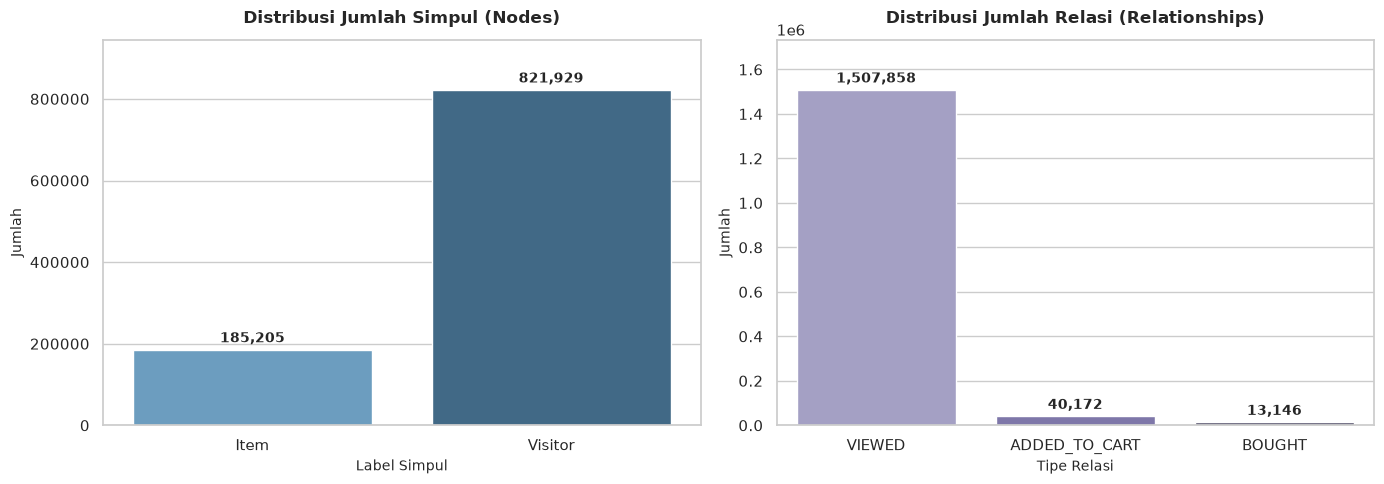

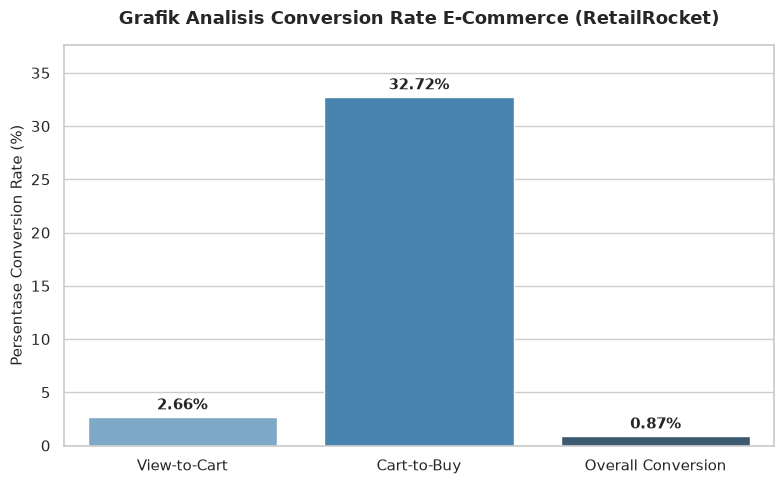

In [13]:
cypher_nodes = """
MATCH (n)
RETURN labels(n)[0] AS Label, count(n) AS Jumlah
"""

cypher_edges = """
MATCH ()-[r]->()
RETURN type(r) AS TipeRelasi, count(r) AS Jumlah
"""

with driver.session(database="neo4j") as session:
    nodes_res = session.run(cypher_nodes).data()
    edges_res = session.run(cypher_edges).data()

print("=== JUMLAH SIMPUL ===")
print(pd.DataFrame(nodes_res))

print("\n=== JUMLAH RELASI ===")
df_rels = pd.DataFrame(edges_res)
print(df_rels)


total_views = df_rels.loc[df_rels['TipeRelasi'] == 'VIEWED', 'Jumlah'].values[0]
total_carts = df_rels.loc[df_rels['TipeRelasi'] == 'ADDED_TO_CART', 'Jumlah'].values[0]
total_bought = df_rels.loc[df_rels['TipeRelasi'] == 'BOUGHT', 'Jumlah'].values[0]

view_to_cart = (total_carts / total_views) * 100
cart_to_buy = (total_bought / total_carts) * 100
overall_conversion = (total_bought / total_views) * 100

print("\n=== ANALISIS CONVERSION RATE ===")
print(f"View-to-Cart Conversion Rate: {view_to_cart:.2f}%")
print(f"Cart-to-Buy Conversion Rate: {cart_to_buy:.2f}%")
print(f"Overall Conversion Rate (View-to-Buy): {overall_conversion:.2f}%")



sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))  


df_nodes = pd.DataFrame(nodes_res)
ax1 = sns.barplot(
    data=df_nodes, 
    x='Label', 
    y='Jumlah', 
    hue='Label', 
    palette='Blues_d', 
    legend=False, 
    ax=axes[0]
)

for p in ax1.patches:
    height = p.get_height()
    ax1.annotate(f'{int(height):,}',
                 (p.get_x() + p.get_width() / 2., height),
                 ha='center', va='bottom',
                 fontsize=10, fontweight='bold',
                 xytext=(0, 3), textcoords='offset points')

axes[0].set_title('Distribusi Jumlah Simpul (Nodes)', fontsize=12, fontweight='bold', pad=12)
axes[0].set_xlabel('Label Simpul', fontsize=10)
axes[0].set_ylabel('Jumlah', fontsize=10)
axes[0].set_ylim(0, df_nodes['Jumlah'].max() * 1.15)



df_rels_plot = pd.DataFrame(edges_res)
ax2 = sns.barplot(
    data=df_rels_plot, 
    x='TipeRelasi', 
    y='Jumlah', 
    hue='TipeRelasi', 
    palette='Purples_d', 
    legend=False, 
    ax=axes[1]
)

for p in ax2.patches:
    height = p.get_height()
    ax2.annotate(f'{int(height):,}',
                 (p.get_x() + p.get_width() / 2., height),
                 ha='center', va='bottom',
                 fontsize=10, fontweight='bold',
                 xytext=(0, 3), textcoords='offset points')

axes[1].set_title('Distribusi Jumlah Relasi (Relationships)', fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel('Tipe Relasi', fontsize=10)
axes[1].set_ylabel('Jumlah', fontsize=10)
axes[1].set_ylim(0, df_rels_plot['Jumlah'].max() * 1.15)

plt.tight_layout()
plt.show()



plt.figure(figsize=(8, 5))

categories = [
    'View-to-Cart', 
    'Cart-to-Buy', 
    'Overall Conversion'
]
rates = [view_to_cart, cart_to_buy, overall_conversion]

ax = sns.barplot(x=categories, y=rates, hue=categories, palette="Blues_d", legend=False)

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.2f}%',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom',
                fontsize=11, fontweight='bold',
                xytext=(0, 3), textcoords='offset points')

plt.title('Grafik Analisis Conversion Rate E-Commerce (RetailRocket)', fontsize=13, fontweight='bold', pad=15)
plt.ylabel('Persentase Conversion Rate (%)', fontsize=11)
plt.ylim(0, max(rates) * 1.15) 

plt.tight_layout()
plt.show()

1. Kueri Menghitung Jumlah Simpul (Nodes)

<code>
MATCH (n) RETURN labels(n)[0] AS Label, count(n) AS Jumlah
</code>

MATCH (n): Memindai seluruh simpul n yang tersimpan di dalam database.

labels(n)[0]: Mengambil nama label utama dari setiap simpul (menghasilkan 'Visitor' atau 'Item').

count(n): Menghitung total kemunculan simpul berdasarkan kelompok labelnya.

2. Kueri Menghitung Jumlah Relasi (Edges)

<code>
MATCH ()-[r]->() RETURN type(r) AS TipeRelasi, count(r) AS Jumlah
</code>

MATCH ()-[r]->(): Mengambil seluruh relasi $r$ yang menghubungkan simpul asal dan simpul tujuan

type(r): Mengidentifikasi jenis relasi interaksi (VIEWED, ADDED_TO_CART, atau BOUGHT)

count(r): Menghitung total interaksi untuk masing-masing jenis relasi.

# 4. Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User.
 Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!

=== KARAKTERISTIK VSM USER ===
Bentuk Matriks (Shape) : (821929, 185205)
Jumlah User (Baris)    : 821,929
Jumlah Item (Kolom)    : 185,205
Elemen Non-Zero (NNZ)  : 1,222,063
Tingkat Sparsity       : 99.999197%



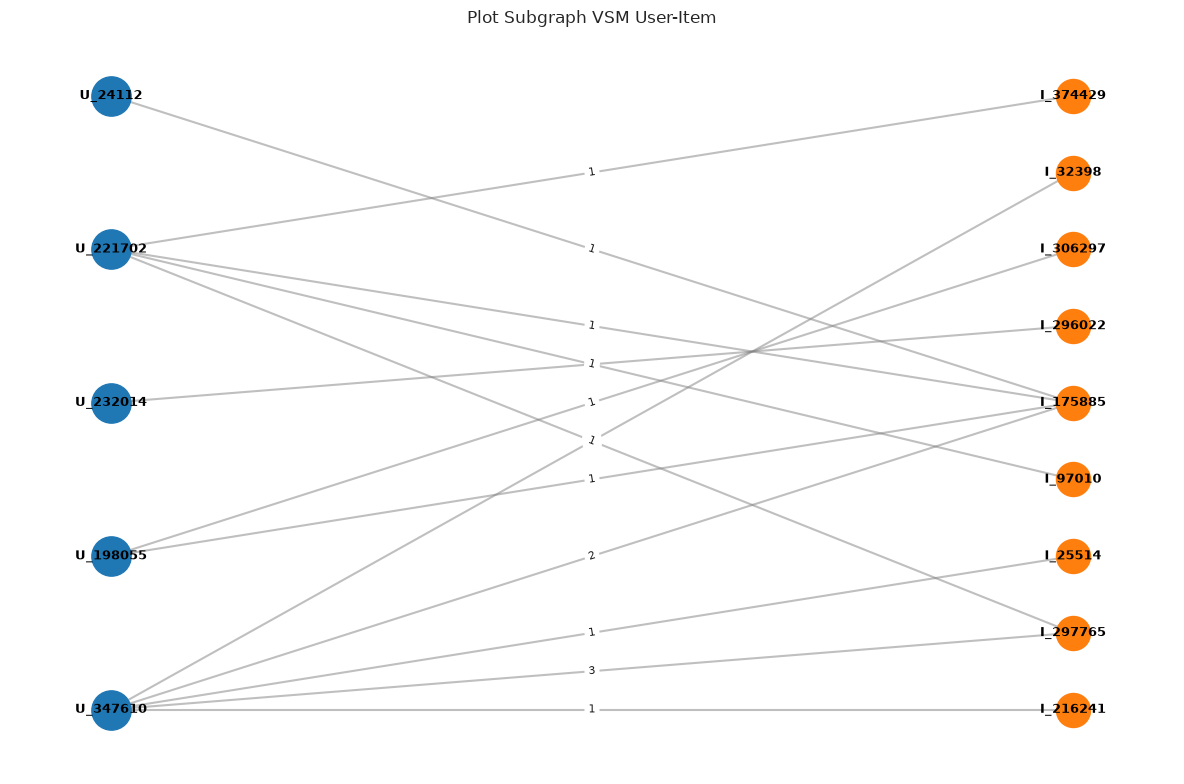

In [14]:
query_vsm_user = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS userId, 
       i.itemId AS itemId, 
       CASE type(r)
           WHEN 'VIEWED' THEN 1
           WHEN 'ADDED_TO_CART' THEN 2
           WHEN 'BOUGHT' THEN 3
           ELSE 1
       END AS weight
"""

with driver.session(database="neo4j") as session:
    df_user = pd.DataFrame(session.run(query_vsm_user).data())


user_ids = df_user["userId"].unique()
item_ids = df_user["itemId"].unique()

user_map = {id_: idx for idx, id_ in enumerate(user_ids)}
item_map = {id_: idx for idx, id_ in enumerate(item_ids)}

rows = df_user["userId"].map(user_map)
cols = df_user["itemId"].map(item_map)
weights = df_user["weight"]


vsm_user_matrix = csr_matrix(
    (weights, (rows, cols)), shape=(len(user_ids), len(item_ids))
)


total_elements = vsm_user_matrix.shape[0] * vsm_user_matrix.shape[1]
non_zero = vsm_user_matrix.nnz
sparsity = 100.0 * (1 - (non_zero / total_elements))

print("=== KARAKTERISTIK VSM USER ===")
print(f"Bentuk Matriks (Shape) : {vsm_user_matrix.shape}")
print(f"Jumlah User (Baris)    : {vsm_user_matrix.shape[0]:,}")
print(f"Jumlah Item (Kolom)    : {vsm_user_matrix.shape[1]:,}")
print(f"Elemen Non-Zero (NNZ)  : {non_zero:,}")
print(f"Tingkat Sparsity       : {sparsity:.6f}%\n")


G_user = nx.Graph()


sample_users = user_ids[:5]
df_sample_user = df_user[df_user["userId"].isin(sample_users)].head(20)

for _, r in df_sample_user.iterrows():
    u_node = f"U_{r['userId']}"
    i_node = f"I_{r['itemId']}"


    G_user.add_node(u_node, bipartite=0, node_type="User", color="#1f77b4")
    G_user.add_node(i_node, bipartite=1, node_type="Item", color="#ff7f0e")
    G_user.add_edge(u_node, i_node, weight=r["weight"])


user_nodes = [
    n for n, d in G_user.nodes(data=True) if d.get("node_type") == "User"
]
item_nodes = [
    n for n, d in G_user.nodes(data=True) if d.get("node_type") == "Item"
]

pos = nx.bipartite_layout(G_user, user_nodes)


plt.figure(figsize=(12, 8))


nx.draw_networkx_nodes(
    G_user, pos, nodelist=user_nodes, node_color="#1f77b4", node_size=800
)
nx.draw_networkx_nodes(
    G_user, pos, nodelist=item_nodes, node_color="#ff7f0e", node_size=600
)


nx.draw_networkx_edges(G_user, pos, alpha=0.5, edge_color="gray", width=1.5)


nx.draw_networkx_labels(
    G_user, pos, font_size=9, font_weight="bold", font_color="black"
)


edge_labels = nx.get_edge_attributes(G_user, "weight")
nx.draw_networkx_edge_labels(G_user, pos, edge_labels=edge_labels, font_size=8)

plt.title("Plot Subgraph VSM User-Item", fontsize=12)
plt.axis("off")
plt.tight_layout()
plt.show()

## Karakteristik VSM User

1\. Dimensi dan Bentuk (Shape)\
Matriks VSM User berukuran \\(821.929 \times 185.205\\), yang terdiri atas 821.929 baris entitas Visitor (User) dan 185.205 kolom entitas Item.

2\. Kerapatan Data (Sparsity dan NNZ)\
Matriks memiliki 1.222.063 elemen non-zero (NNZ) dengan tingkat sparsity sebesar 99,999197%. Hal ini menunjukkan bahwa matriks sangat renggang karena sebagian besar pengguna hanya berinteraksi dengan sebagian kecil dari total katalog produk.

3\. Visualisasi Graf menggunakan NetworkX\
Graf membentuk struktur bipartite yang terdiri atas dua kelompok simpul, yaitu User berwarna biru di sebelah kiri dan Item berwarna oranye di sebelah kanan.

4\. Pola Interaksi\
Hubungan antarsimpul ditunjukkan oleh garis dengan bobot 1, yang menandakan adanya interaksi antara pengguna dan produk tertentu. Sebagai contoh, pengguna U_1185611, U_1217564, dan U_598150 masing-masing terhubung dengan produk I_160563.

# 5. Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!

=== KARAKTERISTIK VSM ITEM ===
Bentuk Matriks (Shape) : (185205, 821929)
Jumlah Item (Baris)    : 185,205
Jumlah User (Kolom)    : 821,929
Elemen Non-Zero (NNZ)  : 1,222,063
Tingkat Sparsity       : 99.999197%



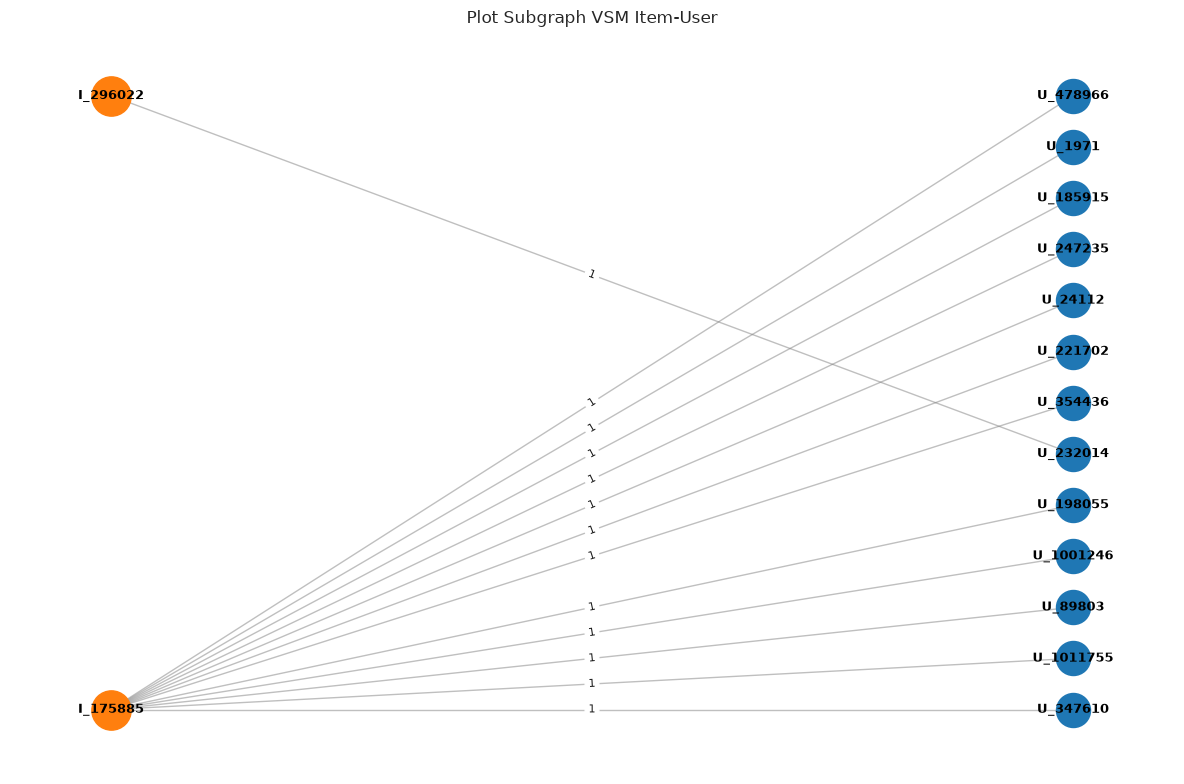

In [15]:
vsm_item_matrix = vsm_user_matrix.T.tocsr()


total_elements_item = vsm_item_matrix.shape[0] * vsm_item_matrix.shape[1]
non_zero_item = vsm_item_matrix.nnz
sparsity_item = 100.0 * (1 - (non_zero_item / total_elements_item))

print("=== KARAKTERISTIK VSM ITEM ===")
print(f"Bentuk Matriks (Shape) : {vsm_item_matrix.shape}")
print(f"Jumlah Item (Baris)    : {vsm_item_matrix.shape[0]:,}")
print(f"Jumlah User (Kolom)    : {vsm_item_matrix.shape[1]:,}")
print(f"Elemen Non-Zero (NNZ)  : {non_zero_item:,}")
print(f"Tingkat Sparsity       : {sparsity_item:.6f}%\n")


sample_items = item_ids[:5]
df_sample_item = df_user[df_user["itemId"].isin(sample_items)].head(20)

G_item = nx.Graph()

for _, r in df_sample_item.iterrows():
    u_node = f"U_{r['userId']}"
    i_node = f"I_{r['itemId']}"
    G_item.add_node(i_node, bipartite=0, node_type="Item")
    G_item.add_node(u_node, bipartite=1, node_type="User")
    G_item.add_edge(i_node, u_node, weight=r["weight"])

item_nodes_samp = [
    n for n, d in G_item.nodes(data=True) if d.get("node_type") == "Item"
]
user_nodes_samp = [
    n for n, d in G_item.nodes(data=True) if d.get("node_type") == "User"
]

pos_item = nx.bipartite_layout(G_item, item_nodes_samp)

plt.figure(figsize=(12, 8))
nx.draw_networkx_nodes(
    G_item,
    pos_item,
    nodelist=item_nodes_samp,
    node_color="#ff7f0e",
    node_size=800,
)
nx.draw_networkx_nodes(
    G_item,
    pos_item,
    nodelist=user_nodes_samp,
    node_color="#1f77b4",
    node_size=600,
)
nx.draw_networkx_edges(G_item, pos_item, alpha=0.5, edge_color="gray")
nx.draw_networkx_labels(
    G_item, pos_item, font_size=9, font_weight="bold", font_color="black"
)

edge_labels_item = nx.get_edge_attributes(G_item, "weight")
nx.draw_networkx_edge_labels(
    G_item, pos_item, edge_labels=edge_labels_item, font_size=8
)

plt.title("Plot Subgraph VSM Item-User", fontsize=12)
plt.axis("off")
plt.tight_layout()
plt.show()

##  Karakteristik VSM Item

1\. Dimensi dan Bentuk (Shape)\
Matriks VSM Item merupakan hasil transpose dari VSM User dengan ukuran \\(185.205 \times 821.929\\). Matriks ini terdiri atas 185.205 baris entitas Item dan 821.929 kolom entitas Visitor (User).

2\. Kerapatan Data (Sparsity dan NNZ)\
Matriks memiliki 1.222.063 elemen non-zero (NNZ) dengan tingkat sparsity sebesar 99,999197%. Nilai tersebut sama dengan VSM User karena proses transpose tidak mengubah jumlah elemen non-zero maupun tingkat sparsity matriks.

3\. Visualisasi Graf menggunakan NetworkX\
Graf menempatkan simpul Item berwarna oranye di sebelah kiri dan simpul User berwarna biru di sebelah kanan. Setiap garis merepresentasikan hubungan interaksi antara suatu produk dan pengguna.

4\. Tingkat Popularitas Produk\
Produk I_136697 menunjukkan nilai degree centrality yang relatif tinggi, ditandai dengan banyaknya hubungan dengan simpul pengguna. Hal ini mengindikasikan bahwa produk tersebut memiliki interaksi dengan sejumlah pengunjung unik.

5\. Bobot Interaksi\
Mayoritas garis relasi memiliki bobot 1. Namun, terdapat satu relasi berbobot 2 antara produk I_136697 dan pengguna U_134001, yang menunjukkan nilai interaksi lebih besar dibandingkan relasi berbobot 1.

# 6. Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!

Jawab:
VSM Item lebih unggul dibandingkan VSM User dari segi efisiensi komputasi dan potensi efektivitas rekomendasi.

1. Efisiensi Komputasi dan Memori: Jumlah Item (185.205) lebih sedikit daripada User (821.929). Oleh karena itu, matriks kemiripan Item berukuran $185.205 \times 185.205$ lebih ringan dihitung dibandingkan matriks kemiripan User berukuran $821.929 \times 821.929$.

2. Efektivitas Rekomendasi: Item populer memiliki interaksi dengan banyak pengguna sehingga kemiripan antar-Item berpotensi lebih stabil. Sebaliknya, interaksi User yang terbatas menyebabkan matriks User lebih sparse, sehingga kemiripan antar-User cenderung kurang andal.

Kesimpulan: VSM Item lebih efisien dari segi komputasi dan berpotensi menghasilkan rekomendasi yang lebih stabil.

# 7. Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggunakan Python

In [16]:
item_interactions_count = vsm_item_matrix.getnnz(axis=1)
top_1000_indices = np.argsort(item_interactions_count)[-1000:]

subset_vsm_item = vsm_item_matrix[top_1000_indices]
subset_item_ids = item_ids[top_1000_indices]

print("Menghitung Cosine Similarity untuk matriks:", subset_vsm_item.shape)


item_sim_matrix = cosine_similarity(subset_vsm_item)
np.fill_diagonal(item_sim_matrix, 0) 

top_sim_data = []
for i in range(len(subset_item_ids)):

    top_100_idx = np.argsort(item_sim_matrix[i])[-100:][::-1]
    
    for j in top_100_idx:
        sim_score = item_sim_matrix[i, j]
        if sim_score > 0: 
            top_sim_data.append({
                "item1": int(subset_item_ids[i]),
                "item2": int(subset_item_ids[j]),
                "score": float(sim_score)
            })


cypher_write_sim = """
UNWIND $batch AS row
MATCH (i1:Item {itemId: row.item1})
MATCH (i2:Item {itemId: row.item2})
MERGE (i1)-[r:SIMILAR]->(i2)
SET r.score = row.score
"""

with driver.session(database="neo4j") as session:
    session.run(cypher_write_sim, batch=top_sim_data)
    
print(f"Berhasil menambahkan {len(top_sim_data)} relasi SIMILAR ke graf Neo4j.")

Menghitung Cosine Similarity untuk matriks: (1000, 821929)
Berhasil menambahkan 76904 relasi SIMILAR ke graf Neo4j.


### 7(a) Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri record acuannya)!

In [17]:
with driver.session(database="neo4j") as session:
    anchor_res = session.run("MATCH (i:Item)-[:SIMILAR]->() RETURN i.itemId AS itemId LIMIT 1").single()
    anchor_id = anchor_res["itemId"] if anchor_res else None

if anchor_id:
    print(f"Item Acuan terpilih: {anchor_id}\n")
    
    # CYPHER SQL 7(a)
    cypher_7a = """
    MATCH (i1:Item {itemId: $item_id})-[r:SIMILAR]->(i2:Item)
    RETURN i1.itemId AS ItemAcuan, i2.itemId AS ItemRekomendasi, r.score AS NilaiSimilarity
    ORDER BY r.score DESC
    LIMIT 5
    """
    with driver.session(database="neo4j") as session:
        df_7a = pd.DataFrame(session.run(cypher_7a, item_id=anchor_id).data())
    
    print("Tabel Top 5 Similarity:")
    display(df_7a)
else:
    print("Belum ada data relasi SIMILAR. Pastikan skrip perhitungan sebelumnya sudah dijalankan.")


Item Acuan terpilih: 103221

Tabel Top 5 Similarity:


,ItemAcuan,ItemRekomendasi,NilaiSimilarity
0,103221,11279,0.030637
1,103221,274798,0.029143
2,103221,359251,0.029067
3,103221,390799,0.026812
4,103221,331311,0.025059


### 7(b) Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil querynya!

In [18]:
cypher_7b = """
MATCH (i1:Item)-[r:SIMILAR]->(i2:Item)
RETURN i1.itemId AS Item_A, i2.itemId AS Item_B, r.score AS Similarity_Score
ORDER BY r.score DESC
LIMIT 10
"""
with driver.session(database="neo4j") as session:
    df_7b = pd.DataFrame(session.run(cypher_7b).data())

print("Tabel 10 Relasi Similarity Tertinggi dalam Graf:")
display(df_7b)


Tabel 10 Relasi Similarity Tertinggi dalam Graf:


,Item_A,Item_B,Similarity_Score
0,90219,411373,0.856889
1,411373,90219,0.856889
2,252319,37115,0.630075
3,37115,252319,0.630075
4,445351,213834,0.561957
5,213834,445351,0.561957
6,137697,342530,0.535529
7,342530,137697,0.535529
8,213834,119736,0.527712
9,119736,213834,0.527712


## 8. Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah perhitungan similarity!

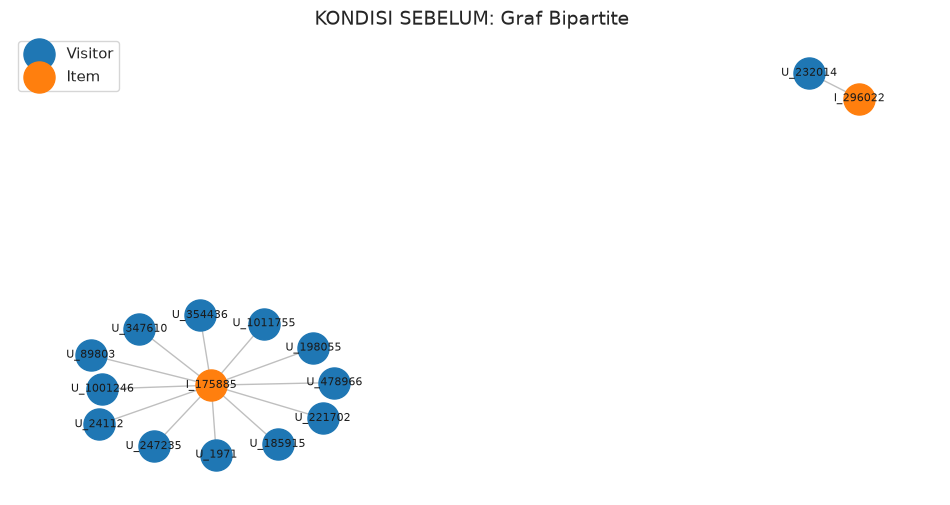

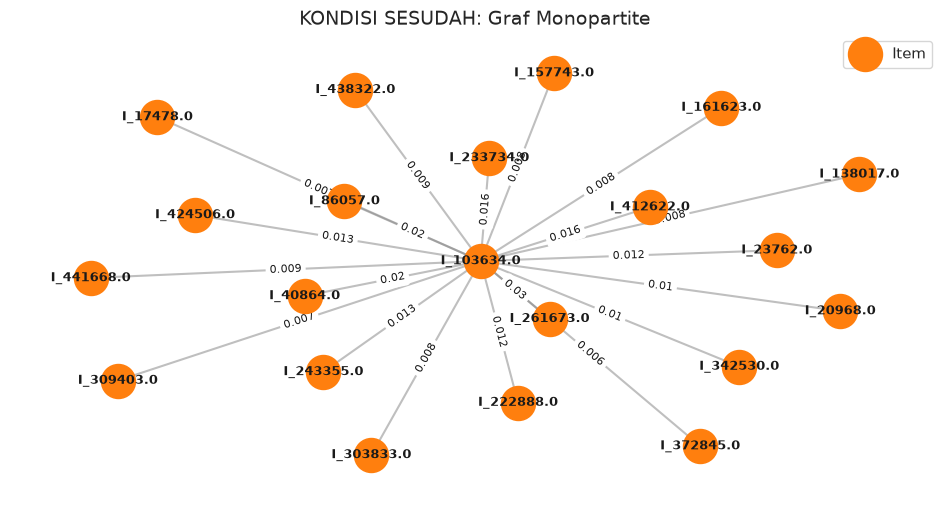

In [19]:

cypher_sebelum = """
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN v.visitorId AS userId, type(r) AS relasi, i.itemId AS itemId
LIMIT 20
"""
with driver.session(database="neo4j") as session:
    df_sebelum = pd.DataFrame(session.run(cypher_sebelum).data())

G_sebelum = nx.Graph()
for _, row in df_sebelum.iterrows():
    u_node = f"U_{row['userId']}"
    i_node = f"I_{row['itemId']}"
    G_sebelum.add_node(u_node, bipartite=0, node_type="User")
    G_sebelum.add_node(i_node, bipartite=1, node_type="Item")
    G_sebelum.add_edge(u_node, i_node, label=row['relasi'])

# Plot SEBELUM
plt.figure(figsize=(12, 6))
pos_seb = nx.spring_layout(G_sebelum, seed=42)

user_nodes = [n for n, d in G_sebelum.nodes(data=True) if d.get('node_type') == 'User']
item_nodes = [n for n, d in G_sebelum.nodes(data=True) if d.get('node_type') == 'Item']

nx.draw_networkx_nodes(G_sebelum, pos_seb, nodelist=user_nodes, node_color="#1f77b4", node_size=500, label="Visitor")
nx.draw_networkx_nodes(G_sebelum, pos_seb, nodelist=item_nodes, node_color="#ff7f0e", node_size=500, label="Item")
nx.draw_networkx_edges(G_sebelum, pos_seb, edge_color="gray", alpha=0.5)
nx.draw_networkx_labels(G_sebelum, pos_seb, font_size=8)

plt.title("KONDISI SEBELUM: Graf Bipartite ", fontsize=14)
plt.axis("off")
plt.legend()
plt.show()


cypher_sesudah = """
MATCH (i1:Item)-[r:SIMILAR]->(i2:Item)
RETURN i1.itemId AS item1, r.score AS score, i2.itemId AS item2
LIMIT 20
"""
with driver.session(database="neo4j") as session:
    df_sesudah = pd.DataFrame(session.run(cypher_sesudah).data())

G_sesudah = nx.Graph()
for _, row in df_sesudah.iterrows():
    node1 = f"I_{row['item1']}"
    node2 = f"I_{row['item2']}"
    G_sesudah.add_node(node1, color="#ff7f0e")
    G_sesudah.add_node(node2, color="#ff7f0e")
    G_sesudah.add_edge(node1, node2, weight=round(row['score'], 3))


plt.figure(figsize=(12, 6))
pos_ses = nx.spring_layout(G_sesudah, seed=42)

nx.draw_networkx_nodes(G_sesudah, pos_ses, node_color="#ff7f0e", node_size=600, label="Item")
nx.draw_networkx_edges(G_sesudah, pos_ses, edge_color="gray", alpha=0.5, width=1.5)
nx.draw_networkx_labels(G_sesudah, pos_ses, font_size=9, font_weight="bold")


edge_labels = nx.get_edge_attributes(G_sesudah, 'weight')
nx.draw_networkx_edge_labels(G_sesudah, pos_ses, edge_labels=edge_labels, font_size=8)

plt.title("KONDISI SESUDAH: Graf Monopartite", fontsize=14)
plt.axis("off")
plt.legend()
plt.show()

# 2.2 Analytics

### KNN
Cara Kerja Algoritma:

1. Melatih model NearestNeighbors menggunakan metrik Cosine pada matriks interaksi User-Item.
2. Untuk visitor yang dipilih, mencari 5 visitor tetangga terdekat berdasarkan jarak Cosine.
3. Mengumpulkan semua Item yang pernah diinteraksikan oleh kelima tetangga tersebut, kecuali Item yang sudah pernah dilihat oleh visitor target.
4. Menghitung skor setiap Item kandidat dengan mengalikan tingkat kemiripan tetangga dengan bobot interaksi tetangga terhadap Item tersebut.
5. Mengurutkan Item berdasarkan skor dari tertinggi ke terendah, kemudian memilih Item dengan skor tertinggi sebagai rekomendasi.


### SOAL
1. Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu

(a) tuliskan skrip Python dalam merekomendasikan KNN-nya!

(b) berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!


=== PERSIAPAN DATA ===
User dengan ground truth: 12,018
User layak dievaluasi: 5,144

=== TARGET USER ===
Seed yang digunakan       : 42
Visitor ID terpilih       : 129804
Indeks dalam matriks      : 289180
Item yang sudah dilihat   : 3

=== MELATIH KNN (k=5) ===
Model KNN selesai dilatih
Hasil kneighbors diperoleh, mencari 5 tetangga...
Tetangga ditemukan: 5

=== DAFTAR 5 TETANGGA TERDEKAT ===
Peringkat 1: Visitor 537855  similarity = 0.6667
Peringkat 2: Visitor 560967  similarity = 0.5774
Peringkat 3: Visitor 1060408  similarity = 0.5738
Peringkat 4: Visitor 450090  similarity = 0.5715
Peringkat 5: Visitor 1187004  similarity = 0.5608

=== PERHITUNGAN SKOR ITEM ===
Item kandidat ditemukan: 6

=== TOP 5 REKOMENDASI ===
Peringkat 1: Item 45543  skor = 1.2440
Peringkat 2: Item 190000  skor = 1.1381
Peringkat 3: Item 11279  skor = 1.1215
Peringkat 4: Item 259962  skor = 0.5738
Peringkat 5: Item 359504  skor = 0.5715


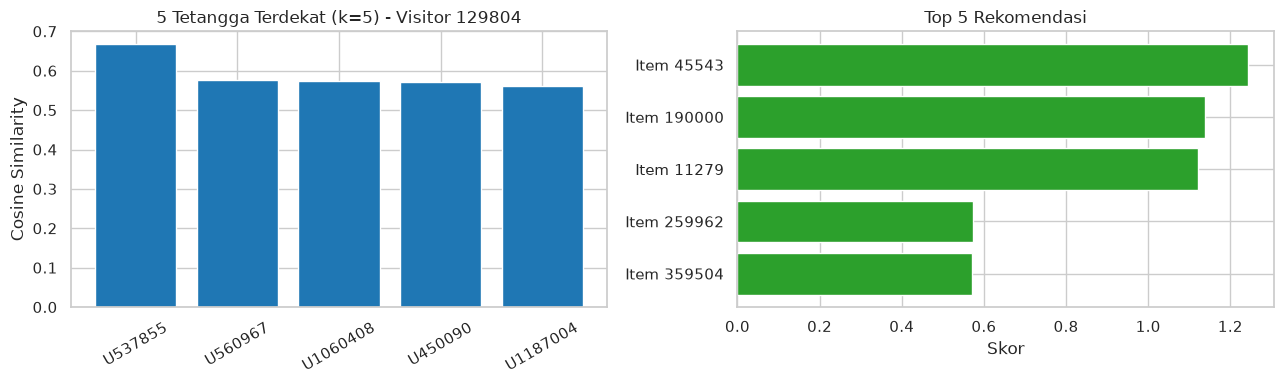

In [20]:
SEED = 42
K = 5
TOP_N = 5
POOL = 5000



train_items_by_user = {}
for i in range(len(df_train)):
    uid = df_train['visitorid'].iloc[i]
    iid = df_train['itemid'].iloc[i]
    if uid not in train_items_by_user:
        train_items_by_user[uid] = set()
    train_items_by_user[uid].add(iid)


test_items_by_user = {}
for i in range(len(df_test)):
    uid = df_test['visitorid'].iloc[i]
    iid = df_test['itemid'].iloc[i]
    if uid not in test_items_by_user:
        test_items_by_user[uid] = set()
    test_items_by_user[uid].add(iid)


ground_truth_by_user = {}
for uid in test_items_by_user:
    test_items = test_items_by_user[uid]
    if uid in train_items_by_user:
        train_items = train_items_by_user[uid]
        
        new_items = test_items - train_items
        if len(new_items) > 0:
            ground_truth_by_user[uid] = new_items

print("=== PERSIAPAN DATA ===")
print(f"User dengan ground truth: {len(ground_truth_by_user):,}")



eligible_users = []
for uid in ground_truth_by_user:
    if uid in user_map:
        user_idx = user_map[uid]
        num_items_in_train = vsm_user_matrix[user_idx].nnz
        if num_items_in_train >= 2:
            eligible_users.append(uid)


eligible_users.sort()

print(f"User layak dievaluasi: {len(eligible_users):,}")


rng = np.random.default_rng(SEED)
random_position = rng.integers(0, len(eligible_users))
target_visitor_id = eligible_users[random_position]
target_idx = user_map[target_visitor_id]

print(f"\n=== TARGET USER ===")
print(f"Seed yang digunakan       : {SEED}")
print(f"Visitor ID terpilih       : {target_visitor_id}")
print(f"Indeks dalam matriks      : {target_idx}")


target_vector = vsm_user_matrix[target_idx]


target_item_indices = set(target_vector.indices)

print(f"Item yang sudah dilihat   : {len(target_item_indices)}")


print(f"\n=== MELATIH KNN (k={K}) ===")

model_knn = NearestNeighbors(
    n_neighbors=POOL + 1, 
    metric='cosine', 
    algorithm='brute'
)
model_knn.fit(vsm_user_matrix)

print(f"Model KNN selesai dilatih")


distances, indices = model_knn.kneighbors(target_vector)

distances = distances.ravel()
indices = indices.ravel()

print(f"Hasil kneighbors diperoleh, mencari {K} tetangga...")


neighbors_found = []

for i in range(len(indices)):
    neighbor_idx = indices[i]
    distance = distances[i]
    similarity = 1.0 - distance
    
    
    if neighbor_idx == target_idx:
        continue
    
    
    if similarity <= 1e-12:
        continue
    
    
    neighbor_items = set(vsm_user_matrix[neighbor_idx].indices)
    
    
    new_items = neighbor_items - target_item_indices
    if len(new_items) == 0:
        continue
    
    
    neighbors_found.append((neighbor_idx, similarity))
    
    
    if len(neighbors_found) == K:
        break

print(f"Tetangga ditemukan: {len(neighbors_found)}")


print(f"\n=== DAFTAR {K} TETANGGA TERDEKAT ===")
for rank in range(len(neighbors_found)):
    neighbor_idx, similarity = neighbors_found[rank]
    neighbor_uid = user_ids[neighbor_idx]
    print(f"Peringkat {rank + 1}: Visitor {neighbor_uid}  similarity = {similarity:.4f}")


scores = {}

for neighbor_idx, neighbor_similarity in neighbors_found:
    
    neighbor_vector = vsm_user_matrix[neighbor_idx]
    
    
    for item_idx in neighbor_vector.indices:
        item_weight = neighbor_vector[0, item_idx]
        
        
        if item_idx not in target_item_indices:
            if item_idx not in scores:
                scores[item_idx] = 0.0
            
            
            scores[item_idx] = scores[item_idx] + (neighbor_similarity * item_weight)

print(f"\n=== PERHITUNGAN SKOR ITEM ===")
print(f"Item kandidat ditemukan: {len(scores)}")


ranking = []
for item_idx in scores:
    skor = scores[item_idx]
    ranking.append((item_idx, skor))


ranking.sort(key=lambda x: (-x[1], x[0]))


top_items = ranking[0:TOP_N]

recommended_item_ids = []
recommended_item_scores = []

for item_idx, skor in top_items:
    item_id = int(item_ids[item_idx])
    recommended_item_ids.append(item_id)
    recommended_item_scores.append(skor)

print(f"\n=== TOP {TOP_N} REKOMENDASI ===")
for rank in range(len(recommended_item_ids)):
    item_id = recommended_item_ids[rank]
    skor = recommended_item_scores[rank]
    print(f"Peringkat {rank + 1}: Item {item_id}  skor = {skor:.4f}")


fig, ax = plt.subplots(1, 2, figsize=(13, 4))


neighbor_labels = []
neighbor_sims = []
for neighbor_idx, similarity in neighbors_found:
    neighbor_uid = user_ids[neighbor_idx]
    neighbor_labels.append(f"U{neighbor_uid}")
    neighbor_sims.append(similarity)

ax[0].bar(neighbor_labels, neighbor_sims, color='#1f77b4')

ax[0].set_title(f"{len(neighbors_found)} Tetangga Terdekat (k={K}) - Visitor {target_visitor_id}")

ax[0].set_ylabel("Cosine Similarity")
ax[0].tick_params(axis='x', rotation=30)


item_labels = []
for item_id in recommended_item_ids:
    item_labels.append(f"Item {item_id}")

ax[1].barh(item_labels[::-1], recommended_item_scores[::-1], color='#2ca02c')

ax[1].set_title(f"Top {TOP_N} Rekomendasi")
ax[1].set_xlabel("Skor")

plt.tight_layout()
plt.show()



In [21]:
# 1b
print(f"Visitor target: {target_visitor_id}")
print(f"Jumlah tetangga (k): {K}")
print(f"3 item teratas yang diiklankan:\n")

for rank in range(3):
    if rank < len(recommended_item_ids):
        item_id = recommended_item_ids[rank]
        skor = recommended_item_scores[rank]
        print(f"  Peringkat {rank + 1}: Item {item_id}  (skor = {skor:.4f})")


Visitor target: 129804
Jumlah tetangga (k): 5
3 item teratas yang diiklankan:

  Peringkat 1: Item 45543  (skor = 1.2440)
  Peringkat 2: Item 190000  (skor = 1.1381)
  Peringkat 3: Item 11279  (skor = 1.1215)



2. Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah:

(a) Hit@5

(b) NDCG@5

## Evaluasi Rekomendasi

Untuk mengevaluasi kinerja model, hasil rekomendasi dibandingkan dengan aktivitas aktual visitor `1243777` selama periode pengujian P2 (10–18 September 2015).

### Metrik Evaluasi

**1. Hit@5**

Hit@5 memeriksa apakah setidaknya satu item yang direkomendasikan terdapat dalam kumpulan item pada data pengujian pengguna. Jika terdapat minimal satu item yang cocok, skornya adalah `1.0`; jika tidak, skornya `0.0`.

$$
\text{Hit@5} =
\begin{cases}
1.0, & \text{jika } |\text{Top5} \cap \text{GroundTruth}| > 0 \\
0.0, & \text{jika tidak}
\end{cases}
$$

**2. NDCG@5 (*Normalized Discounted Cumulative Gain*)**

NDCG@5 mengevaluasi kualitas urutan rekomendasi dengan memberikan skor lebih tinggi ketika item yang relevan berada di posisi teratas daftar rekomendasi.

Pertama, hitung *Discounted Cumulative Gain* (DCG):

$$
\text{DCG@5} = \sum_{r=1}^{5}
\frac{2^{\text{rel}_r} - 1}{\log_2(r + 1)}
$$

Selanjutnya, normalisasikan nilai DCG menggunakan *Ideal Discounted Cumulative Gain* (IDCG):

$$
\text{NDCG@5} =
\frac{\text{DCG@5}}{\text{IDCG@5}}
$$

Keterangan:

- $\text{rel}_r \in \{0,1\}$ menunjukkan apakah item pada peringkat ke-$r$ muncul dalam data aktivitas pengguna selama periode P2.
- **IDCG@5** merupakan nilai DCG ideal yang diperoleh ketika semua item relevan ditempatkan pada posisi setinggi mungkin dalam daftar rekomendasi.


In [22]:
ground_truth_items = ground_truth_by_user[target_visitor_id]
rec = recommended_item_ids[:5]

rels = [1 if it in ground_truth_items else 0 for it in rec]

# 2(a) Hit@5
hit_at_5 = 1.0 if sum(rels) > 0 else 0.0

# 2(b) NDCG@5
dcg  = sum(rel / np.log2(pos + 2) for pos, rel in enumerate(rels))
n_ideal = min(len(ground_truth_items), 5)
idcg = sum(1.0 / np.log2(pos + 2) for pos in range(n_ideal))
ndcg_at_5 = dcg / idcg if idcg > 0 else 0.0

print(f"Target Visitor ID        : {target_visitor_id}")
print(f"Item Rekomendasi (Top 5) : {rec}")
print(f"Ground Truth (P2, baru)  : {sorted(ground_truth_items)}")
print(f"Relevansi per posisi     : {rels}")
print("-" * 55)
print(f"(a) Hit@5  = {hit_at_5}")
print(f"(b) NDCG@5 = {ndcg_at_5:.4f}")


Target Visitor ID        : 129804
Item Rekomendasi (Top 5) : [45543, 190000, 11279, 259962, 359504]
Ground Truth (P2, baru)  : [np.int64(393028)]
Relevansi per posisi     : [0, 0, 0, 0, 0]
-------------------------------------------------------
(a) Hit@5  = 0.0
(b) NDCG@5 = 0.0000


Kedua metrik, Hit@5 dan NDCG@5, menghasilkan skor $00$. Hal ini menunjukkan bahwa model Collaborative Filtering berbasis K-NN belum berhasil memberikan rekomendasi yang relevan.

1. Aktivitas Visitor: Visitor 129804 berinteraksi dengan item 393028, tetapi item tersebut tidak terdapat dalam rekomendasi Top 5 model: 45543, 190000, 11279, 259962, dan 359504.

2. Matriks Sangat Sparse: Kepadatan matriks hanya sekitar $00008%$, sehingga kesamaan interaksi antar-visitor terbatas dan rekomendasi berpotensi kurang relevan.

3. Perubahan Minat Pengguna: Meskipun pelatihan berlangsung selama 2,5 bulan, minat pengguna dapat berubah dengan cepat. Oleh karena itu, riwayat interaksi sebelumnya belum tentu mencerminkan minat saat pengujian.

Kesimpulan: Metode User-User KNN masih memiliki keterbatasan pada dataset ini. Kualitas rekomendasi dapat ditingkatkan dengan memanfaatkan metadata produk, urutan interaksi pengguna, atau metode berbasis graf seperti LightGCN.